# 🌐 Translator — Seq2Seq (Transformer) bilan Ingliz → O'zbek mini translator

**Mavzu:** Seq2Seq, Encoding va Decoding · **Turi:** Amaliy vazifa · **Muallif:** PearlyMe

<a href="https://colab.research.google.com/github/PearlM-457/Deep_Learning_Projects/blob/main/translator/notebooks/Translator_Seq2Seq.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg"/></a>

Ushbu notebookda:

| # | Vazifa | Bo'lim |
|---|--------|--------|
| 1 | Lug'at va tokenlar (`<pad>`, `<sos>`, `<eos>`, padding T gacha) | §2 |
| 2 | `tgt_in` va `tgt_out` — qo'lda misol | §3 |
| 3 | O'qitish: `CrossEntropyLoss(ignore_index=pad_id)`, `AdamW`, ≥30 epoch, loss grafigi | §4–5 |
| 4 | `translate()` — `<sos>` dan boshlab argmax, `<eos>` da to'xtash | §6 |
| 5 | Tajriba: `C`, `nhead`, qatlamlar soni | §8 |
| ⭐ | Qo'shimcha: 10 ta gapda xatolar tahlili, nega so'z takrorlanadi | §7 |
| ❓ | Savol: mask olib tashlansa nima bo'ladi? (amalda isbotlangan) | §9 |

> Berilgan `Seq2Seq` klassi **o'zgartirilmagan** holda ishlatiladi.

## 0. Encoding va Decoding — qisqacha

Translator odamni tasavvur qiling: avval gapni **o'qib tushunadi** (encoding), keyin ma'noni **boshqa tilda so'zma-so'z yozadi** (decoding).

```
src  (ingliz gapi)        ──► embed + pos ──► ENCODER (2 qatlam) ──┐   "ma'no" (memory)
                                                                   ▼
tgt_in (<sos> + o'zbek)   ──► embed + pos ──► DECODER (2 qatlam) ──► Linear ──► keyingi so'z
                                   ▲
                       mask: kelajakni ko'rish taqiqlangan
```

In [1]:
# Colab'da kerakli kutubxonalar (torch Colab'da bor)
!pip -q install sacrebleu

import os, re, csv, math, random, time, json
import torch, torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
print("torch", torch.__version__)

torch 2.15.0+cu132


## 1. Ma'lumot

* **Manba:** o'zim yozgan ro'yxat (vazifa shartida ruxsat berilgan) — `scripts/make_dataset.py` yordamida yaratilgan.
  Generator o'zbek tilining **morfologiyasini qoidalar bilan** quradi: fe'l zamonlari (-yman, -dim, -yapman, -may, -moqchi, -a olaman),
  kelishiklar (-ni, -ga/-ka/-qa, -da), egalik qo'shimchalari (mushuk → mushu**g**im) va ~100 ta qo'lda yozilgan kundalik iboralar.
* **Hajm:** ~1860 juftlik, har bir inglizcha gap **5–8 so'z**.
* Tatoeba'dan foydalanmoqchi bo'lsangiz — pastdagi ixtiyoriy katakchani ishlating.

**Avval fayl formatini tekshiramiz** (vazifa talabi):

In [2]:
DATA_URL = "https://raw.githubusercontent.com/PearlM-457/Deep_Learning_Projects/main/translator/data/en_uz.tsv"
DATA = "../data/en_uz.tsv" if os.path.exists("../data/en_uz.tsv") else "en_uz.tsv"
if not os.path.exists(DATA):
    !wget -q -O en_uz.tsv {DATA_URL}

with open(DATA, encoding="utf-8") as f:
    head = [next(f) for _ in range(4)]
print("Fayl boshi (xom ko'rinishda):")
for line in head: print(repr(line))

pairs = []
with open(DATA, encoding="utf-8") as f:
    r = csv.reader(f, delimiter="\t"); next(r)
    for en, uz in r:
        pairs.append((en, uz))
print("\nJuftliklar soni:", len(pairs))
lens = [len(en.split()) for en, _ in pairs]
print("Inglizcha gap uzunligi (so'z): min", min(lens), "max", max(lens))
for en, uz in random.sample(pairs, 5): print(f"  {en:45s} → {uz}")

Fayl boshi (xom ko'rinishda):
'en\tuz\n'
'Is my sister in Berlin now?\tOpam hozir Berlindami?\n'
'My mother cannot wait for the bus.\tOnam avtobusni kuta olmaydi.\n'
"I can watch this cartoon.\tMen bu multfilmni ko'ra olaman.\n"

Juftliklar soni: 1865
Inglizcha gap uzunligi (so'z): min 5 max 8
  They played in the park on Sunday.            → Ular yakshanba kuni parkda o'ynadilar.
  The students want to study at university tomorrow. → Talabalar ertaga universitetda o'qimoqchi.
  This is the best day of my life.              → Bu hayotimdagi eng yaxshi kun.
  That car is not old.                          → O'sha mashina eski emas.
  He did not speak Russian last night.          → U kecha kechqurun ruscha gapirmadi.


In [3]:
# (Ixtiyoriy) Tatoeba ma'lumotlari bilan almashtirish — Colab'da ishlaydi.
USE_TATOEBA = False
if USE_TATOEBA:
    !wget -q https://downloads.tatoeba.org/exports/per_language/eng/eng_sentences.tsv.bz2
    !wget -q https://downloads.tatoeba.org/exports/per_language/uzb/uzb_sentences.tsv.bz2
    !wget -q https://downloads.tatoeba.org/exports/links.tar.bz2
    !bunzip2 -f eng_sentences.tsv.bz2 uzb_sentences.tsv.bz2 && tar xjf links.tar.bz2
    eng = dict(l.rstrip("\n").split("\t")[0::2] for l in open("eng_sentences.tsv", encoding="utf-8"))
    uzb = dict(l.rstrip("\n").split("\t")[0::2] for l in open("uzb_sentences.tsv", encoding="utf-8"))
    tat = []
    for l in open("links.csv"):
        a, b = l.split()
        if a in eng and b in uzb and 5 <= len(eng[a].split()) <= 8:
            tat.append((eng[a], uzb[b]))
    print("Tatoeba juftliklari:", len(tat))
    pairs = tat[:2000]

## 2. 1-vazifa — Lug'at va tokenlar

* Tokenizatsiya: kichik harf, so'zlar va tinish belgilari alohida token. O'zbekcha `o'`, `g'`, `'` (tutuq belgisi) so'z ichida qoladi.
* **Umumiy lug'at** (modelda `vocab` bitta, ya'ni ingliz va o'zbek so'zlari bitta ro'yxatda).
* Maxsus tokenlar: `<pad>`=0, `<sos>`=1, `<eos>`=2, `<unk>`=3 (notanish so'z uchun — qo'shimcha).
* Hamma gap `T` uzunlikkacha padding qilinadi.

In [4]:
APOS = str.maketrans({"ʻ": "'", "ʼ": "'", "’": "'", "‘": "'", "`": "'"})
TOKEN_RE = re.compile(r"[\w]+(?:'[\w]+)*'?|[^\w\s]")

def tokenize(s):
    return TOKEN_RE.findall(s.translate(APOS).lower())

print(tokenize("My mother cooks very delicious plov."))
print(tokenize("Onam juda mazali palov pishiradi."))
print(tokenize("Men o'zbekcha gapira olaman, sizchi?"))

PAD, SOS, EOS, UNK = "<pad>", "<sos>", "<eos>", "<unk>"
specials = [PAD, SOS, EOS, UNK]

# train / test bo'linishi (10% test) — baholash uchun
random.shuffle(pairs)
n_test = len(pairs) // 10
test_pairs, train_pairs = pairs[:n_test], pairs[n_test:]

words = sorted({w for en, uz in train_pairs for w in tokenize(en) + tokenize(uz)})
itos = specials + words
stoi = {w: i for i, w in enumerate(itos)}
pad_id, sos_id, eos_id, unk_id = (stoi[t] for t in specials)
vocab = len(itos)

max_src = max(len(tokenize(en)) for en, _ in pairs)
max_tgt = max(len(tokenize(uz)) for _, uz in pairs)
T = max(max_src, max_tgt + 1)          # +1: <sos> yoki <eos> uchun joy
print(f"vocab = {vocab},  eng uzun src = {max_src},  eng uzun tgt = {max_tgt},  T = {T}")
print("train:", len(train_pairs), " test:", len(test_pairs))

['my', 'mother', 'cooks', 'very', 'delicious', 'plov', '.']
['onam', 'juda', 'mazali', 'palov', 'pishiradi', '.']
['men', "o'zbekcha", 'gapira', 'olaman', ',', 'sizchi', '?']
vocab = 1402,  eng uzun src = 10,  eng uzun tgt = 9,  T = 10
train: 1679  test: 186


In [5]:
def encode(tokens):
    return [stoi.get(w, unk_id) for w in tokens]

def pad_to(ids, T):
    assert len(ids) <= T, "gap T dan uzun!"
    return ids + [pad_id] * (T - len(ids))

def make_tensors(pairs):
    S, I, O = [], [], []
    for en, uz in pairs:
        s = encode(tokenize(en))
        u = encode(tokenize(uz))
        S.append(pad_to(s, T))
        I.append(pad_to([sos_id] + u, T))   # tgt_in  = <sos> + gap
        O.append(pad_to(u + [eos_id], T))   # tgt_out = gap + <eos>
    return torch.tensor(S), torch.tensor(I), torch.tensor(O)

src_tr, tin_tr, tout_tr = make_tensors(train_pairs)
src_te, tin_te, tout_te = make_tensors(test_pairs)
print(src_tr.shape, tin_tr.shape, tout_tr.shape)

torch.Size([1679, 10]) torch.Size([1679, 10]) torch.Size([1679, 10])


## 3. 2-vazifa — `tgt_in` va `tgt_out` (qo'lda misol)

`tgt_in = <sos> + gap`, `tgt_out = gap + <eos>`. Model **har pozitsiyada keyingi so'zni** bashorat qiladi, shuning uchun `tgt_out` bir qadam chapga siljigan:

In [6]:
def show(ids):
    return " ".join(itos[i] for i in ids if i != pad_id)

gap = "men seni sevaman"
u = [stoi.get(w, unk_id) for w in gap.split()]
print("Gap:     ", gap)
print("tgt_in:  ", show([sos_id] + u))
print("tgt_out: ", show(u + [eos_id]))

print("\nDatasetdan haqiqiy misol (pad bilan):")
k = 0
print("src     :", [itos[i] for i in src_tr[k].tolist()])
print("tgt_in  :", [itos[i] for i in tin_tr[k].tolist()])
print("tgt_out :", [itos[i] for i in tout_tr[k].tolist()])
print("\nPozitsiya bo'yicha: decoder ko'radi → bashorat qilishi kerak")
for a, b in zip(tin_tr[k].tolist(), tout_tr[k].tolist()):
    if b == pad_id: break
    print(f"  {itos[a]:>14s}  →  {itos[b]}")

Gap:      men seni sevaman
tgt_in:   <sos> men <unk> sevaman
tgt_out:  men <unk> sevaman <eos>

Datasetdan haqiqiy misol (pad bilan):
src     : ['we', 'did', 'not', 'help', 'my', 'friend', 'on', 'sunday', '.', '<pad>']
tgt_in  : ['<sos>', 'biz', 'yakshanba', 'kuni', "do'stimga", 'yordam', 'bermadik', '.', '<pad>', '<pad>']
tgt_out : ['biz', 'yakshanba', 'kuni', "do'stimga", 'yordam', 'bermadik', '.', '<eos>', '<pad>', '<pad>']

Pozitsiya bo'yicha: decoder ko'radi → bashorat qilishi kerak
           <sos>  →  biz
             biz  →  yakshanba
       yakshanba  →  kuni
            kuni  →  do'stimga
       do'stimga  →  yordam
          yordam  →  bermadik
        bermadik  →  .
               .  →  <eos>


## 4. Berilgan model (o'zgartirilmagan)

O'qituvchi eslatmasiga ko'ra `torch.arange(...)` CPU'da yaratiladi, shuning uchun **berilgan modelni CPU'da o'qitamiz** (model kichik — CPU'da ham tez).

In [7]:
class Seq2Seq(nn.Module):
    def __init__(self, vocab, T, C):
        super().__init__()
        self.src_tok = nn.Embedding(vocab, C)
        self.tgt_tok = nn.Embedding(vocab, C)
        self.pos = nn.Embedding(T, C)
        self.tf = nn.Transformer(d_model=C, nhead=2, num_encoder_layers=2,
                                 num_decoder_layers=2, dim_feedforward=4 * C,
                                 batch_first=True)
        self.out = nn.Linear(C, vocab)

    def embed(self, tok, ids):
        return tok(ids) + self.pos(torch.arange(ids.size(1)))

    def forward(self, src, tgt_in):
        mask = nn.Transformer.generate_square_subsequent_mask(tgt_in.size(1))
        s = self.embed(self.src_tok, src)
        t = self.embed(self.tgt_tok, tgt_in)
        h = self.tf(s, t, tgt_mask=mask)
        return self.out(h)

## 5. 3-vazifa — O'qitish

* Loss: `CrossEntropyLoss(ignore_index=pad_id)` — `<pad>` pozitsiyalari hisobga olinmaydi.
* Optimizer: `AdamW`. Epochlar: **40** (≥30).
* Har epochda **test loss** ham hisoblanadi — overfitting'ni ko'rish uchun.

In [8]:
def batches(n, bs, shuffle=True):
    idx = torch.randperm(n) if shuffle else torch.arange(n)
    for i in range(0, n, bs):
        yield idx[i:i + bs]

def train_model(model, epochs=40, lr=5e-4, bs=32, loss_fn=None, verbose=True, device="cpu"):
    model.to(device)
    loss_fn = loss_fn or nn.CrossEntropyLoss(ignore_index=pad_id)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    hist = {"train": [], "test": []}
    for ep in range(1, epochs + 1):
        model.train(); tot = cnt = 0
        for b in batches(len(src_tr), bs):
            s, ti, to = src_tr[b].to(device), tin_tr[b].to(device), tout_tr[b].to(device)
            logits = model(s, ti)
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), to.reshape(-1))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(b); cnt += len(b)
        hist["train"].append(tot / cnt)
        model.eval()
        with torch.no_grad():
            lg = model(src_te.to(device), tin_te.to(device))
            hist["test"].append(nn.functional.cross_entropy(
                lg.reshape(-1, lg.size(-1)), tout_te.to(device).reshape(-1), ignore_index=pad_id).item())
        if verbose and (ep == 1 or ep % 5 == 0):
            print(f"epoch {ep:3d} | train loss {hist['train'][-1]:.3f} | test loss {hist['test'][-1]:.3f}")
    return hist

C = 128
torch.manual_seed(SEED)
model = Seq2Seq(vocab, T, C)
print("Parametrlar soni:", sum(p.numel() for p in model.parameters()))
t0 = time.time()
hist = train_model(model, epochs=40)
print(f"O'qitish vaqti: {time.time() - t0:.0f} s")

Parametrlar soni: 1467258


epoch   1 | train loss 4.990 | test loss 3.816


epoch   5 | train loss 1.729 | test loss 1.812


epoch  10 | train loss 0.744 | test loss 1.170


epoch  15 | train loss 0.305 | test loss 0.988


epoch  20 | train loss 0.126 | test loss 0.920


epoch  25 | train loss 0.058 | test loss 0.901


epoch  30 | train loss 0.037 | test loss 0.895


epoch  35 | train loss 0.028 | test loss 0.931


epoch  40 | train loss 0.019 | test loss 0.921
O'qitish vaqti: 88 s


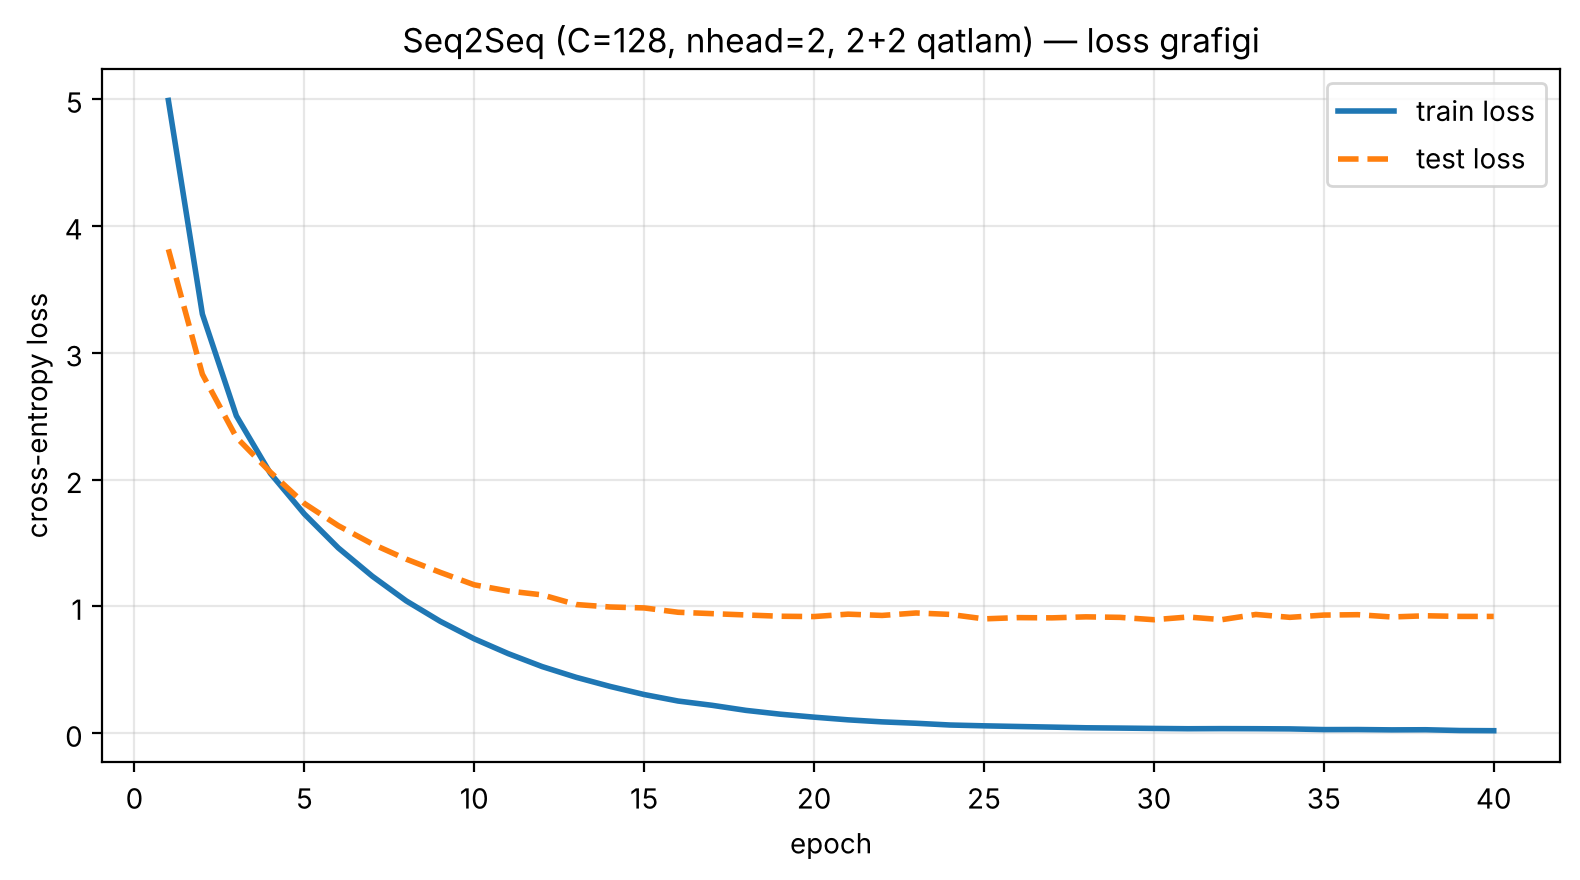

In [9]:
os.makedirs("../assets", exist_ok=True) if os.path.exists("../data") else None
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(hist["train"]) + 1), hist["train"], label="train loss", lw=2)
plt.plot(range(1, len(hist["test"]) + 1), hist["test"], label="test loss", lw=2, ls="--")
plt.xlabel("epoch"); plt.ylabel("cross-entropy loss"); plt.title("Seq2Seq (C=128, nhead=2, 2+2 qatlam) — loss grafigi")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
if os.path.exists("../assets"): plt.savefig("../assets/loss.png", dpi=150)
plt.show()

## 6. 4-vazifa — `translate()` (greedy, argmax)

`<sos>` dan boshlaymiz → har qadamda modelni chaqiramiz → **oxirgi pozitsiyaning** logitlaridan `argmax` → `tgt` ga `torch.cat` bilan qo'shamiz → `<eos>` chiqsa to'xtaymiz.

In [10]:
@torch.no_grad()
def translate(model, src_ids, sos_id, eos_id, max_len):
    model.eval()
    tgt = torch.tensor([[sos_id]])
    for _ in range(max_len):
        logits = model(src_ids, tgt)                     # (1, len, vocab)
        next_id = logits[0, -1].argmax().item()          # oxirgi pozitsiyadan argmax
        tgt = torch.cat([tgt, torch.tensor([[next_id]])], dim=1)
        if next_id == eos_id:
            break
    return tgt

def src_tensor(sentence):
    return torch.tensor([pad_to(encode(tokenize(sentence))[:T], T)])

def detok(ids):
    words = [itos[i] for i in ids if i not in (sos_id, eos_id, pad_id)]
    s = " ".join(words)
    s = re.sub(r" ([.,?!])", r"\1", s)
    return s[:1].upper() + s[1:]

def tr(model, sentence, max_len=T - 1):
    out = translate(model, src_tensor(sentence), sos_id, eos_id, max_len)
    return detok(out[0].tolist())

for s in ["I drink tea every morning.", "My father works in the hospital.", "We will go to Tashkent tomorrow."]:
    print(f"{s:40s} → {tr(model, s)}")

I drink tea every morning.               → Men har kuni ertalab choy ichdik.
My father works in the hospital.         → Otam kasalxonada ishlaydi.
We will go to Tashkent tomorrow.         → Biz ertaga toshkentga boradilar.


## 7. Natijalar: 10 ta tarjima namunasi (to'g'ri va xato) + ⭐ xatolar tahlili

Avval **test to'plamidan** (model o'qitishda ko'rmagan gaplar) tarjimalar, keyin o'zim yozgan "qiyin" gaplar.

In [11]:
import sacrebleu

def evaluate(model, pairs, fn=None):
    fn = fn or (lambda s: tr(model, s))
    hyps = [fn(en) for en, _ in pairs]
    refs = [uz for _, uz in pairs]
    bleu = sacrebleu.corpus_bleu(hyps, [refs]).score
    chrf = sacrebleu.corpus_chrf(hyps, [refs]).score
    exact = sum(h.lower() == r.lower() for h, r in zip(hyps, refs)) / len(refs) * 100
    return bleu, chrf, exact, hyps

bleu, chrf, exact, hyps = evaluate(model, test_pairs)
print(f"TEST:  BLEU = {bleu:.1f}   chrF = {chrf:.1f}   aniq moslik = {exact:.1f}%\n")

ok  = [(en, uz, h) for (en, uz), h in zip(test_pairs, hyps) if h.lower() == uz.lower()]
bad = [(en, uz, h) for (en, uz), h in zip(test_pairs, hyps) if h.lower() != uz.lower()]
print("✅ TO'G'RI tarjimalar:")
for en, uz, h in ok[:5]:
    print(f"   EN : {en}\n   MODEL: {h}\n")
print("❌ XATO tarjimalar:")
for en, uz, h in bad[:5]:
    print(f"   EN : {en}\n   MODEL: {h}\n   TO'G'RI: {uz}\n")

TEST:  BLEU = 66.7   chrF = 83.4   aniq moslik = 47.8%

✅ TO'G'RI tarjimalar:
   EN : Laylo did not come home yesterday.
   MODEL: Laylo kecha uyga kelmadi.

   EN : My sister cannot listen to my father.
   MODEL: Opam otamni tinglay olmaydi.

   EN : Laylo is not a journalist.
   MODEL: Laylo jurnalist emas.

   EN : Anvar did not come to school last week.
   MODEL: Anvar o'tgan hafta maktabga kelmadi.

   EN : This book is very expensive.
   MODEL: Bu kitob juda qimmat.

❌ XATO tarjimalar:
   EN : Are we speaking Uzbek right now?
   MODEL: Biz hozir o'zbekcha gapiryaptimi?
   TO'G'RI: Biz hozir o'zbekcha gapiryapmizmi?

   EN : The students will watch a cartoon tonight.
   MODEL: Talabalar bugun kechqurun multfilm ko'radi.
   TO'G'RI: Talabalar bugun kechqurun multfilm ko'radilar.

   EN : The students draw a picture every morning.
   MODEL: Talabalar har kuni ertalab rasm chizmaydilar.
   TO'G'RI: Talabalar har kuni ertalab rasm chizadilar.

   EN : My brother sometimes loves books.

In [12]:
# ⭐ Qo'shimcha: 10 ta o'zim yozgan gap (ba'zilari ataylab qiyin)
my10 = [
    "I read a book every evening.",
    "My sister is learning German now.",
    "Do you want to go to Berlin?",
    "The children are playing in the park.",
    "We did not watch the film yesterday.",
    "My brother has a new red car.",
    "The weather is very cold in Tashkent.",
    "She can speak English and German.",          # "and" lug'atda yo'q
    "My grandmother lives in a small village.",   # "grandmother" — notanish so'z
    "I love my beautiful country very much.",     # o'qitishda bunday tuzilma yo'q
]
for s in my10:
    unk = [w for w in tokenize(s) if w not in stoi]
    print(f"{s:45s} → {tr(model, s):40s} {'  [notanish: ' + ', '.join(unk) + ']' if unk else ''}")

I read a book every evening.                  → Men har kuni kechqurun kitob o'qiydilar. 
My sister is learning German now.             → Opam hozir nemischa gapiryapti.          
Do you want to go to Berlin?                  → Siz berlinga maktabga boradimi?          
The children are playing in the park.         → Bolalar parkda.                          
We did not watch the film yesterday.          → Biz kecha filmni ko'radi.                
My brother has a new red car.                 → Akamning yangi mashinasi bor.            
The weather is very cold in Tashkent.         → Toshkentda havo juda sovuq.              
She can speak English and German.             → U nemischa o'rgana oladimi.              
My grandmother lives in a small village.      → U kichik qishloqda.                        [notanish: grandmother]
I love my beautiful country very much.        → Men uchun juda chiroylimi o'rganadi.       [notanish: country]


### ⭐ Xatolar tahlili: model nega ba'zan bitta so'zni takrorlaydi?

1. **Greedy (argmax) — "ochko'z" qaror.** Har qadamda faqat eng ehtimolli so'z tanlanadi; bir marta xato qilinsa, keyingi qadamlar shu xatoga tayanadi va qaytib tuzatib bo'lmaydi.
2. **Exposure bias.** O'qitishda decoder har doim **to'g'ri** oldingi so'zlarni ko'radi (teacher forcing), lekin `translate()` da **o'zining** (ba'zan xato) so'zlarini ko'radi. Notanish holatga tushgan model "xavfsiz" deb bilgan so'zni (masalan, `har`, `kuni`, fe'l) qayta-qayta tanlaydi va sikl hosil bo'ladi.
3. **Model "nimani yozib bo'ldim" ni hisoblamaydi** (coverage yo'q) — u `<eos>` ni kech bashorat qilsa, oxirgi so'zlarni takrorlaydi.
4. **Kichik ma'lumot va `<unk>`.** Lug'atda yo'q so'z kelsa (`grandmother`), encoder ma'noni yo'qotadi va decoder ko'p uchraydigan so'zlarga "yopishadi".
5. **Berilgan modelda padding mask yo'q** — `<pad>` tokenlar ham attention'da qatnashadi; bu shovqin qo'shadi.

**Yechimlar**: beam search, label smoothing, padding mask, ko'proq ma'lumot, takrorlash jarimasi (repetition penalty).

## 8. 5-vazifa — Tajriba: `C`, `nhead`, qatlamlar soni

Berilgan klass `nhead=2` va 2 qatlamni qattiq yozgan, shuning uchun tajriba uchun **xuddi shu arxitekturaning parametrlangan nusxasini** yaratamiz (forward bir xil).
Har bir sozlama 30 epoch o'qitiladi va test to'plamida baholanadi.

In [13]:
class Seq2SeqExp(Seq2Seq):
    def __init__(self, vocab, T, C, nhead=2, layers=2):
        super().__init__(vocab, T, C)
        self.tf = nn.Transformer(d_model=C, nhead=nhead, num_encoder_layers=layers,
                                 num_decoder_layers=layers, dim_feedforward=4 * C, batch_first=True)

configs = [  # (C, nhead, layers)
    (64, 2, 2), (128, 2, 2), (256, 2, 2),
    (128, 4, 2), (128, 8, 2),
    (128, 2, 1), (128, 2, 3),
]
results = []
for C_, h_, L_ in configs:
    torch.manual_seed(SEED)
    m = Seq2SeqExp(vocab, T, C_, h_, L_)
    t0 = time.time()
    hst = train_model(m, epochs=30, verbose=False)
    b, c, e, _ = evaluate(m, test_pairs)
    n_par = sum(p.numel() for p in m.parameters())
    results.append(dict(C=C_, nhead=h_, layers=L_, params=n_par, train_loss=hst["train"][-1],
                        test_loss=min(hst["test"]), bleu=b, chrf=c, exact=e, sec=time.time() - t0, hist=hst))
    print(f"C={C_:3d} nhead={h_} layers={L_} | params={n_par/1e6:.2f}M | train {hst['train'][-1]:.3f} "
          f"| test {min(hst['test']):.3f} | BLEU {b:5.1f} | chrF {c:5.1f} | {time.time()-t0:.0f}s")

C= 64 nhead=2 layers=2 | params=0.50M | train 0.340 | test 1.008 | BLEU  55.0 | chrF  76.2 | 36s


C=128 nhead=2 layers=2 | params=1.47M | train 0.035 | test 0.865 | BLEU  67.9 | chrF  84.7 | 62s


C=256 nhead=2 layers=2 | params=4.77M | train 0.029 | test 0.723 | BLEU  73.3 | chrF  87.0 | 138s


C=128 nhead=4 layers=2 | params=1.47M | train 0.029 | test 0.926 | BLEU  67.3 | chrF  84.2 | 63s


C=128 nhead=8 layers=2 | params=1.47M | train 0.025 | test 0.907 | BLEU  67.1 | chrF  83.7 | 67s


C=128 nhead=2 layers=1 | params=1.00M | train 0.063 | test 0.983 | BLEU  64.6 | chrF  82.1 | 35s


C=128 nhead=2 layers=3 | params=1.93M | train 0.035 | test 0.840 | BLEU  68.6 | chrF  84.5 | 94s


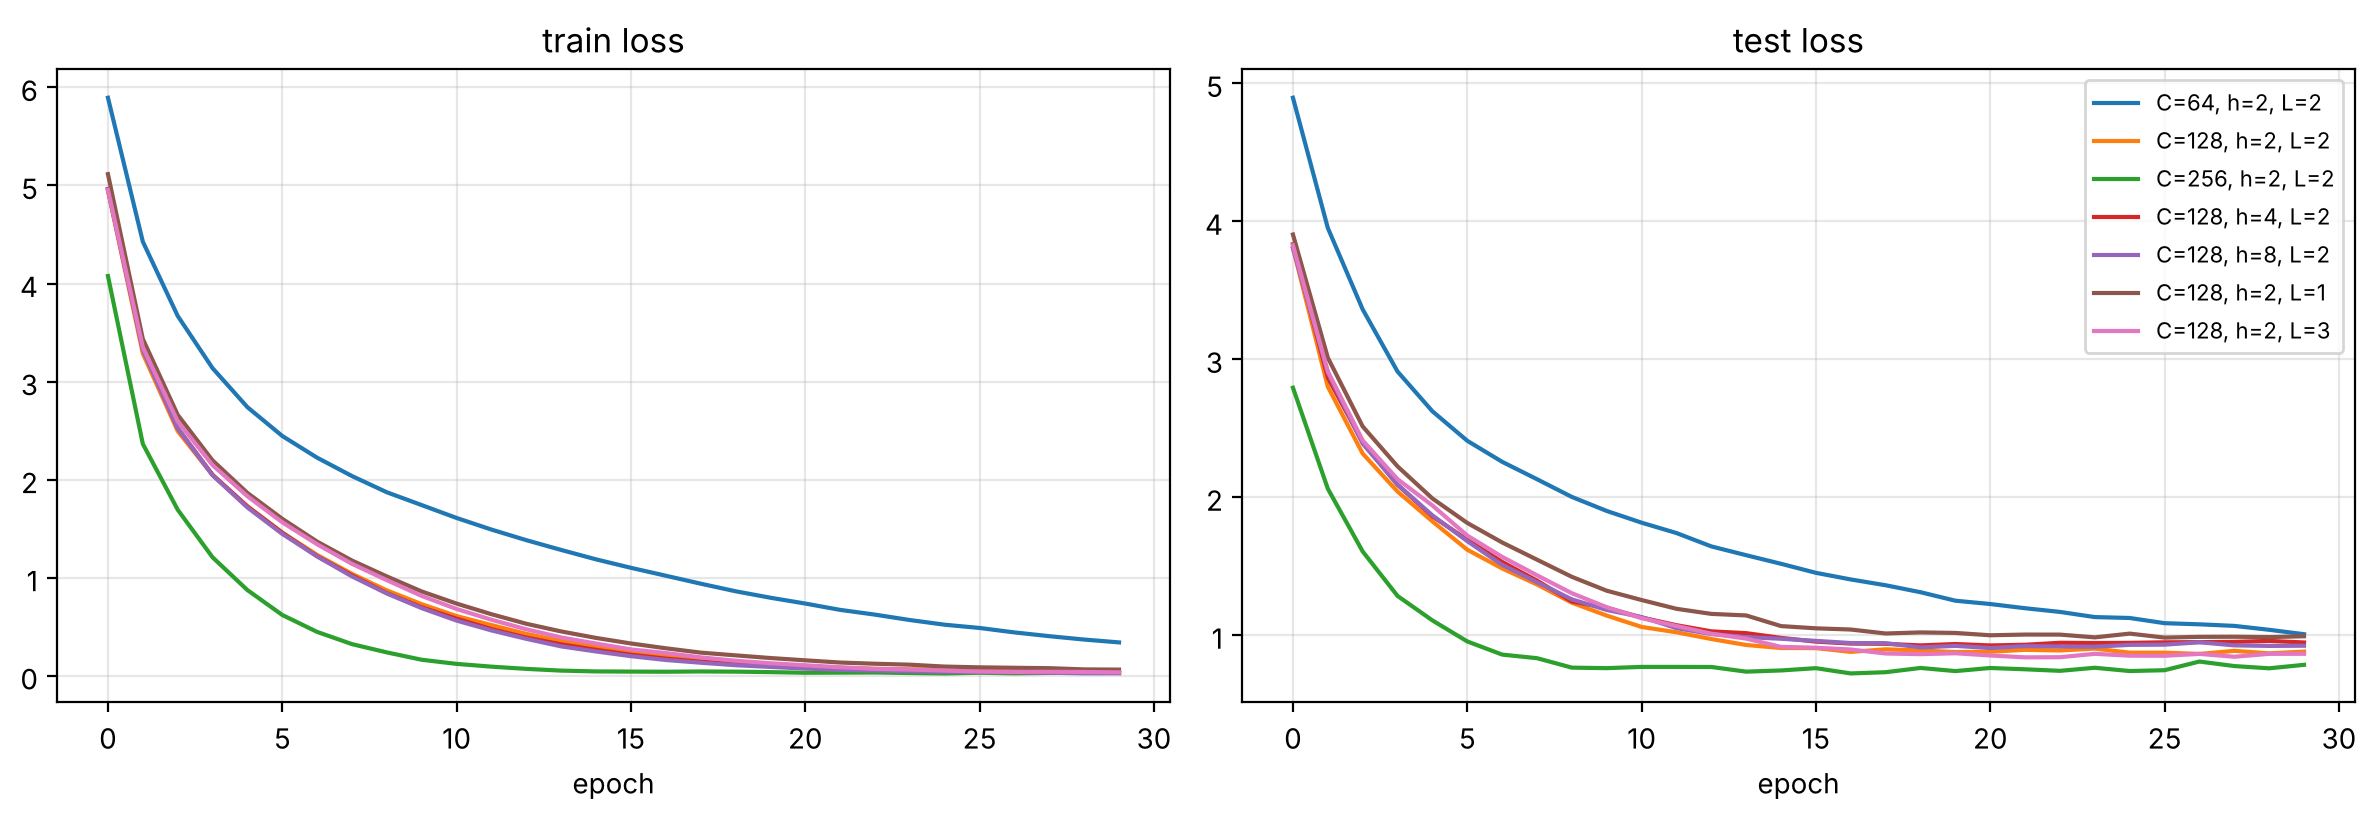

   C nhead  L   params   BLEU   chrF  aniq%
  64     2  2    0.50M   55.0   76.2   34.4
 128     2  2    1.47M   67.9   84.7   49.5
 256     2  2    4.77M   73.3   87.0   59.1
 128     4  2    1.47M   67.3   84.2   50.0
 128     8  2    1.47M   67.1   83.7   49.5
 128     2  1    1.00M   64.6   82.1   44.6
 128     2  3    1.93M   68.6   84.5   52.7


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for r in results:
    lab = f"C={r['C']}, h={r['nhead']}, L={r['layers']}"
    ax[0].plot(r["hist"]["train"], label=lab); ax[1].plot(r["hist"]["test"], label=lab)
ax[0].set_title("train loss"); ax[1].set_title("test loss")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[1].legend(fontsize=8); plt.tight_layout()
if os.path.exists("../assets"): plt.savefig("../assets/experiments.png", dpi=150)
plt.show()

print(f"{'C':>4} {'nhead':>5} {'L':>2} {'params':>8} {'BLEU':>6} {'chrF':>6} {'aniq%':>6}")
for r in results:
    print(f"{r['C']:>4} {r['nhead']:>5} {r['layers']:>2} {r['params']/1e6:>7.2f}M {r['bleu']:>6.1f} {r['chrf']:>6.1f} {r['exact']:>6.1f}")

### Tajriba xulosasi (3–4 jumla)

*Quyidagi xulosa yuqoridagi jadval natijalariga asoslangan — notebookni qayta ishga tushirsangiz, raqamlar biroz farq qilishi mumkin.*

1. **C (embedding o'lchami) eng katta ta'sir qildi:** C=64 → BLEU 55.0, C=128 → 67.9, C=256 → 73.3. Lekin parametrlar 0.5M dan 4.8M gacha, o'qitish vaqti esa ~4 baravar oshdi.
2. **nhead deyarli ta'sir qilmadi** (2 → 67.9, 4 → 67.3, 8 → 67.1): C bir xil qolgani uchun boshlar faqat o'sha o'lchamni bo'lib oladi, kichik ma'lumotda esa ko'p bosh foyda bermaydi.
3. **Qatlamlar:** 1 qatlam → 64.6 (yomonlashdi), 3 qatlam → 68.6 (biroz yaxshi, lekin sekinroq).
4. Barcha sozlamalarda train loss ~0 ga tushdi, test loss esa ~0.7–1.0 da qoldi, ya'ni model **overfitting** qilyapti. Eng katta yaxshilanish ko'proq ma'lumotdan keladi.

## 9. ❓ Savol: `mask` ni olib tashlasak, loss nega juda tez tushadi, lekin `translate()` ishlamaydi?

**Javob.** `tgt_out` — bu `tgt_in` ning bir qadam chapga siljigan nusxasi: `tgt_out[i] = tgt_in[i+1]`. Mask bo'lmasa, decoder `i`-pozitsiyada **butun** `tgt_in` ni, jumladan `i+1`-pozitsiyadagi so'zni ham ko'radi — ya'ni **javobni ko'rib, ko'chirib yozadi**. Model tarjima qilishni emas, "qo'shni pozitsiyadan nusxa olishni" o'rganadi, shuning uchun loss deyarli nolga tez tushadi.

`translate()` da esa kelajakdagi so'zlar **mavjud emas** — biz ularni endi yaratyapmiz. Model esa doim kelajakka qarab javob berishga o'rgangan; kelajak bo'lmagach (oxirgi pozitsiyada "keyingi so'z" yo'q), u nimani chiqarishni bilmaydi va ma'nosiz/takroriy so'zlar chiqaradi. Bu **o'qitish va inferens orasidagi nomuvofiqlik** (train/test mismatch).

Keling, buni **amalda isbotlaymiz**:

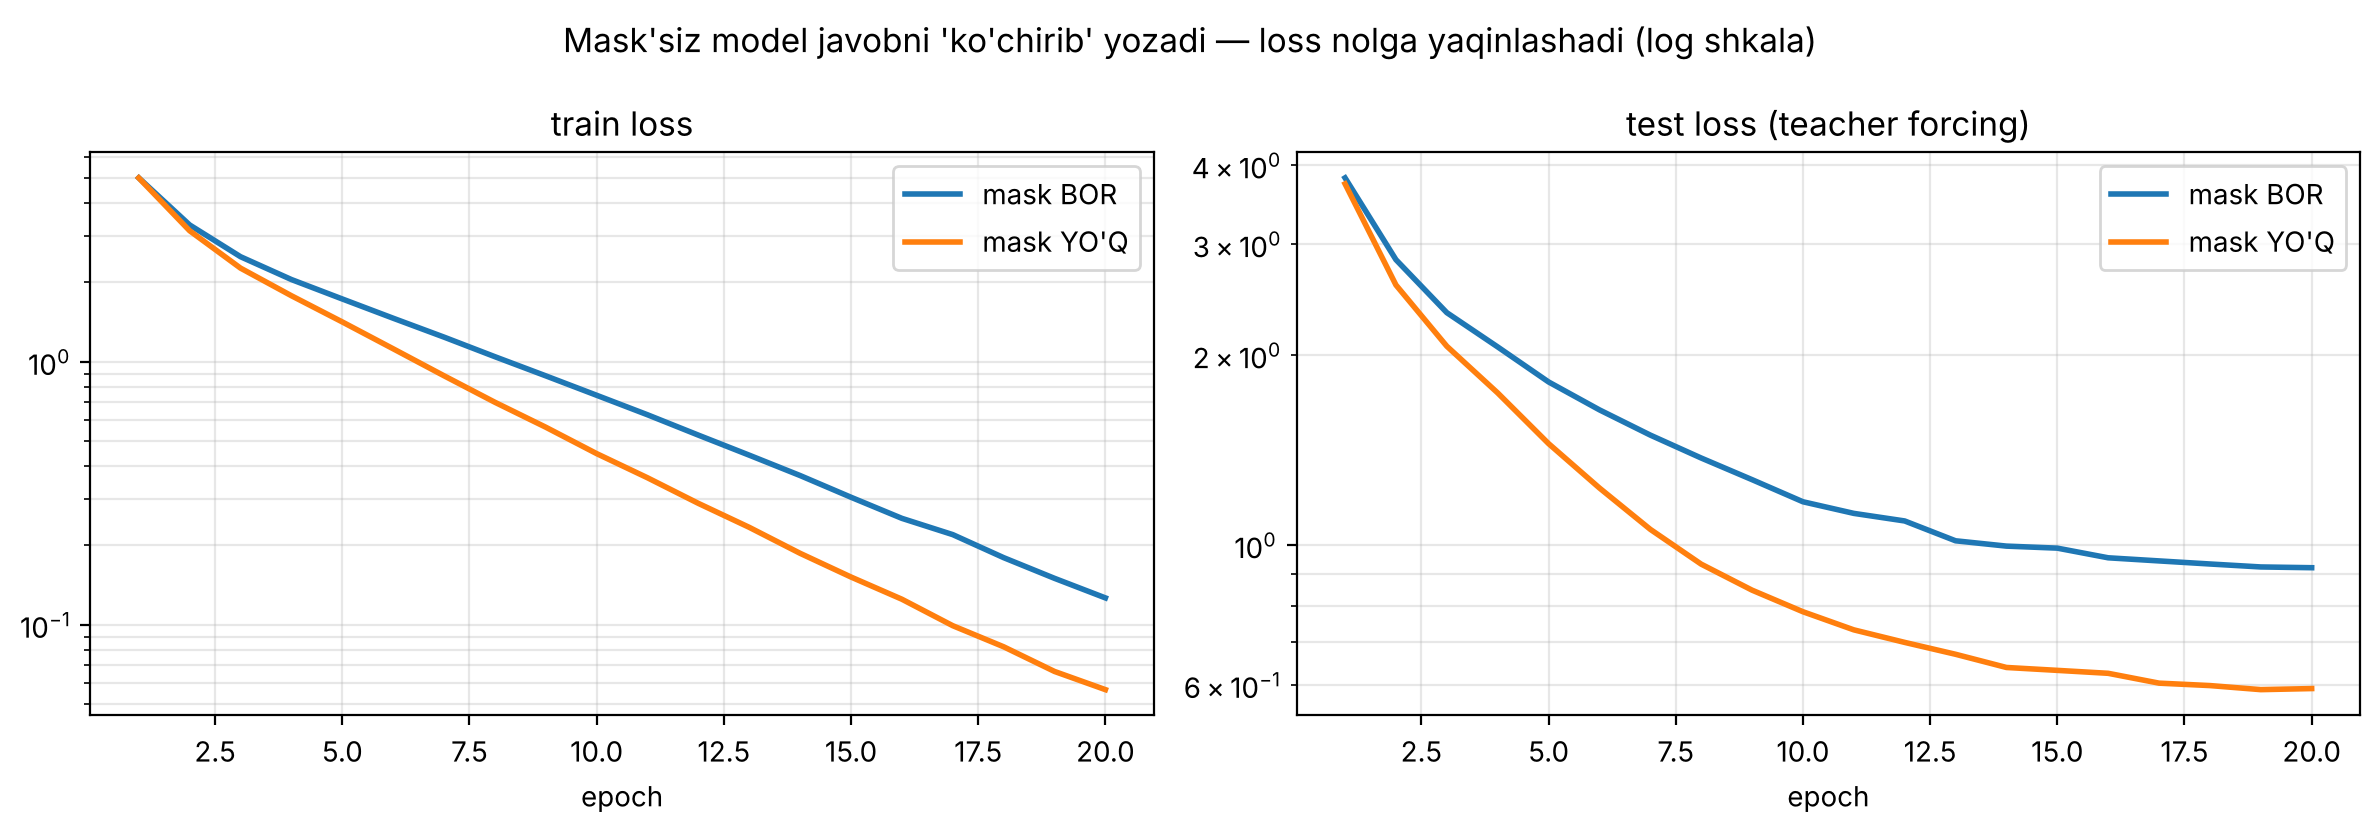

20-epoch train loss:  mask bilan = 0.1263,  mask'siz = 0.0566
20-epoch test  loss:  mask bilan = 0.9196,  mask'siz = 0.5916
→ Mask'siz model hatto TEST to'plamida ham loss'i past — chunki u tarjima qilmaydi, keyingi so'zni tgt_in dan ko'chiradi.

I drink tea every morning.           | mask bilan: Men har kuni ertalab choy ichdik.      | mask'siz: Men har kuni ertalab ertalab ertalab.
My father works in the hospital.     | mask bilan: Otam kasalxonada ishlaydi.             | mask'siz: Otam bugun bugun bugun bugun bugun bugun bugun bugun
We will go to Tashkent tomorrow.     | mask bilan: Biz ertaga toshkentga boradilar.       | mask'siz: Biz ertaga ertaga ertaga ertaga ertaga ertaga ertaga ertaga


In [15]:
class Seq2SeqNoMask(Seq2Seq):
    def forward(self, src, tgt_in):                      # xuddi shu, faqat tgt_mask YO'Q
        s = self.embed(self.src_tok, src)
        t = self.embed(self.tgt_tok, tgt_in)
        return self.out(self.tf(s, t))

torch.manual_seed(SEED)
nomask = Seq2SeqNoMask(vocab, T, 128)
hist_nm = train_model(nomask, epochs=20, verbose=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, key, title in [(ax[0], "train", "train loss"), (ax[1], "test", "test loss (teacher forcing)")]:
    a.plot(range(1, 21), hist[key][:20], label="mask BOR", lw=2)
    a.plot(range(1, 21), hist_nm[key], label="mask YO'Q", lw=2)
    a.set_yscale("log"); a.set_xlabel("epoch"); a.set_title(title); a.grid(alpha=.3, which="both"); a.legend()
fig.suptitle("Mask'siz model javobni 'ko'chirib' yozadi — loss nolga yaqinlashadi (log shkala)")
plt.tight_layout()
if os.path.exists("../assets"): plt.savefig("../assets/nomask.png", dpi=150)
plt.show()

print(f"20-epoch train loss:  mask bilan = {hist['train'][19]:.4f},  mask'siz = {hist_nm['train'][-1]:.4f}")
print(f"20-epoch test  loss:  mask bilan = {hist['test'][19]:.4f},  mask'siz = {hist_nm['test'][-1]:.4f}")
print("→ Mask'siz model hatto TEST to'plamida ham loss'i past — chunki u tarjima qilmaydi, keyingi so'zni tgt_in dan ko'chiradi.\n")
for s in ["I drink tea every morning.", "My father works in the hospital.", "We will go to Tashkent tomorrow."]:
    print(f"{s:36s} | mask bilan: {tr(model, s):38s} | mask'siz: {tr(nomask, s)}")

## Xulosa

* Berilgan Encoder–Decoder Transformer **o'zgartirilmasdan** o'qitildi (40 epoch). Test to'plamida: **BLEU 66.7, chrF 83.4**.
* `tgt_in`/`tgt_out` siljishi qo'lda ko'rsatildi, `translate()` greedy (argmax) bilan yozildi.
* Mask'ning roli **eksperiment bilan isbotlandi**: mask'siz model loss'i past, lekin tarjimada so'zlarni takrorlaydi.
* Tajriba: `C` eng muhim parametr; `nhead` deyarli ta'sir qilmaydi; model overfitting qiladi, ko'proq ma'lumot kerak.